# Détection d'étoiles sur image astronomique synthétique

Pipeline : génération d'un fond bruité → ajout de *n* étoiles → visualisation → détection → affichage des ellipses (style Siril).

## 1. Imports

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy import ndimage as ndi
from scipy.optimize import curve_fit

rng = np.random.default_rng(42)  # graine pour la reproductibilité

## 2. Génération d'une fausse image astronomique bruitée

Fond de ciel + léger gradient (pollution lumineuse) + vignettage, puis bruit de photons (Poisson) et bruit de lecture (gaussien).

In [12]:
def generate_noisy_background(shape=(512, 512), sky_level=200.0, gradient=40.0,
                              vignetting=0.15, read_noise=5.0, rng=rng):
    """Retourne une image (float) de fond de ciel bruité, en ADU."""
    ny, nx = shape
    y, x = np.mgrid[0:ny, 0:nx]

    # Gradient linéaire diagonal
    grad = gradient * (x / nx + y / ny) / 2

    # Vignettage : assombrissement vers les bords
    r2 = ((x - nx / 2) ** 2 + (y - ny / 2) ** 2) / ((nx / 2) ** 2 + (ny / 2) ** 2)
    vig = 1 - vignetting * r2

    clean_sky = (sky_level + grad) * vig
    photon_noise = rng.poisson(clean_sky).astype(float)         # bruit de photons
    readout = rng.normal(0, read_noise, size=shape)             # bruit de lecture
    return photon_noise + readout


background = generate_noisy_background()
print(f"Image : {background.shape}, médiane = {np.median(background):.1f} ADU, "
      f"écart-type = {background.std():.1f} ADU")

Image : (512, 512), médiane = 209.1 ADU, écart-type = 18.4 ADU


## 3. Ajout de *n* étoiles à des positions aléatoires

Chaque étoile est une gaussienne 2D (légèrement elliptique, orientée aléatoirement) avec un flux tiré selon une loi de puissance (beaucoup d'étoiles faibles, peu de brillantes).

In [13]:
def draw_star(img, x0, y0, flux, fwhm, e, theta, rng=rng):
    """Ajoute une étoile gaussienne elliptique (avec bruit de photons) à img, in-place."""
    ny, nx = img.shape
    sigma = fwhm / (2 * np.sqrt(2 * np.log(2)))
    sx, sy = sigma * (1 + e), sigma * (1 - e)

    # Stamp local pour rester rapide
    half = int(np.ceil(6 * sx))
    xi0, xi1 = int(max(0, x0 - half)), int(min(nx, x0 + half + 1))
    yi0, yi1 = int(max(0, y0 - half)), int(min(ny, y0 + half + 1))
    if xi0 >= xi1 or yi0 >= yi1:
        return
    yy, xx = np.mgrid[yi0:yi1, xi0:xi1]
    dx, dy = xx - x0, yy - y0
    xr = dx * np.cos(theta) + dy * np.sin(theta)
    yr = -dx * np.sin(theta) + dy * np.cos(theta)
    profile = np.exp(-0.5 * ((xr / sx) ** 2 + (yr / sy) ** 2))
    stamp = flux * profile / profile.sum()
    img[yi0:yi1, xi0:xi1] += rng.poisson(np.clip(stamp, 0, None))   # bruit de photons de l'étoile


def add_stars(image, n_stars=60, fwhm_range=(3.0, 5.0), flux_range=(200, 15000),
              ellipticity_max=0.25, margin=15, rng=rng):
    """Ajoute n_stars étoiles à l'image.
    Retourne (nouvelle image, vérité terrain [x, y, flux, fwhm, e, theta])."""
    img = image.copy()
    ny, nx = img.shape

    # Flux en loi de puissance : beaucoup de faibles, peu de brillantes
    u = rng.uniform(size=n_stars)
    fmin, fmax = flux_range
    fluxes = fmin * (fmax / fmin) ** u ** 2

    truth = []
    for flux in fluxes:
        x0 = rng.uniform(margin, nx - margin)
        y0 = rng.uniform(margin, ny - margin)
        fwhm = rng.uniform(*fwhm_range)
        e = rng.uniform(0, ellipticity_max)
        theta = rng.uniform(0, np.pi)
        draw_star(img, x0, y0, flux, fwhm, e, theta, rng)
        truth.append((x0, y0, flux, fwhm, e, theta))

    return img, np.array(truth)


N_STARS = 60
image, truth = add_stars(background, n_stars=N_STARS)
print(f"{N_STARS} étoiles ajoutées.")

60 étoiles ajoutées.


## 4. Visualisation de l'image

Étirement `asinh` entre des percentiles, comme le fait un « auto-stretch » en astrophoto.

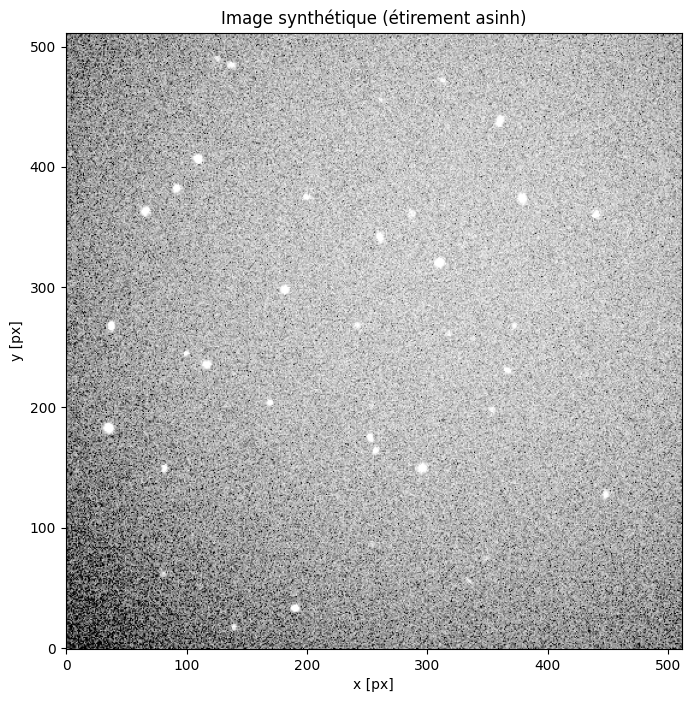

In [14]:
def stretch(img, lo_pct=1, hi_pct=99.7):
    lo, hi = np.percentile(img, [lo_pct, hi_pct])
    norm = np.clip((img - lo) / (hi - lo), 0, 1)
    return np.arcsinh(10 * norm) / np.arcsinh(10)


fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(stretch(image), cmap="gray", origin="lower")
ax.set_title("Image synthétique (étirement asinh)")
ax.set_xlabel("x [px]"); ax.set_ylabel("y [px]")
plt.show()

## 5. Détection des étoiles

1. Estimation du fond (médiane filtrée large) et du bruit (MAD)
2. Lissage gaussien pour augmenter le S/B
3. Seuillage + maxima locaux
4. Ajustement d'une gaussienne 2D elliptique (centroïde, σx, σy, angle θ) → FWHM, comme dans Siril

In [15]:
def gauss2d(coords, amp, x0, y0, sx, sy, theta, offset):
    """Gaussienne 2D elliptique (sx, sy = sigmas le long des axes tournés de theta)."""
    x, y = coords
    dx, dy = x - x0, y - y0
    xr = dx * np.cos(theta) + dy * np.sin(theta)
    yr = -dx * np.sin(theta) + dy * np.cos(theta)
    return offset + amp * np.exp(-0.5 * ((xr / sx) ** 2 + (yr / sy) ** 2))


def detect_stars(img, nsigma=5.0, smooth_sigma=1.5, bg_box=64,
                 min_separation=6, cutout=7, fwhm_min=1.5, fwhm_max=12.0):
    """Détecte les étoiles et retourne une liste de dictionnaires."""
    # --- Fond et bruit -------------------------------------------------
    bg = ndi.median_filter(ndi.zoom(img, 1 / 4, order=1), size=bg_box // 4)
    bg = ndi.zoom(bg, 4, order=1)[:img.shape[0], :img.shape[1]]
    resid = img - bg
    noise = 1.4826 * np.median(np.abs(resid - np.median(resid)))   # MAD -> sigma

    # --- Lissage et seuillage ------------------------------------------
    smooth = ndi.gaussian_filter(resid, smooth_sigma)
    noise_s = 1.4826 * np.median(np.abs(smooth - np.median(smooth)))
    threshold = nsigma * noise_s

    # --- Maxima locaux --------------------------------------------------
    local_max = (smooth == ndi.maximum_filter(smooth, size=2 * min_separation + 1))
    ys, xs = np.nonzero(local_max & (smooth > threshold))

    k = 2 * np.sqrt(2 * np.log(2))                                  # sigma -> FWHM
    stars = []
    for y, x in zip(ys, xs):
        y0, y1 = max(0, y - cutout), min(img.shape[0], y + cutout + 1)
        x0, x1 = max(0, x - cutout), min(img.shape[1], x + cutout + 1)
        stamp = resid[y0:y1, x0:x1]
        yy, xx = np.mgrid[y0:y1, x0:x1]

        p0 = [stamp.max(), x, y, 1.8, 1.8, 0.0, 0.0]
        bounds = ([0, x - 3, y - 3, 0.5, 0.5, -np.pi, -np.inf],
                  [np.inf, x + 3, y + 3, fwhm_max / k, fwhm_max / k, np.pi, np.inf])
        try:
            popt, _ = curve_fit(gauss2d, (xx.ravel(), yy.ravel()), stamp.ravel(),
                                p0=p0, bounds=bounds, maxfev=2000)
        except (RuntimeError, ValueError):
            continue

        amp, xc, yc, sx, sy, theta, off = popt
        fwhm_a, fwhm_b = k * max(sx, sy), k * min(sx, sy)
        if sy > sx:
            theta += np.pi / 2
        fwhm = np.sqrt(fwhm_a * fwhm_b)
        if not (fwhm_min < fwhm < fwhm_max):
            continue

        stars.append(dict(x=xc, y=yc, fwhm_a=fwhm_a, fwhm_b=fwhm_b,
                          theta=np.degrees(theta), fwhm=fwhm,
                          amp=amp, flux=2 * np.pi * amp * sx * sy))
    return stars, bg, noise


stars, bg, noise = detect_stars(image)
print(f"Bruit estimé : {noise:.2f} ADU")
print(f"{len(stars)} étoiles détectées sur {N_STARS} injectées")
print(f"FWHM médiane mesurée : {np.median([s['fwhm'] for s in stars]):.2f} px "
      f"(injectée : {np.median(truth[:, 3]):.2f} px)")

Bruit estimé : 15.38 ADU
38 étoiles détectées sur 60 injectées
FWHM médiane mesurée : 3.93 px (injectée : 4.08 px)


## 6. Image et ellipses autour des étoiles détectées (style Siril)

Les ellipses sont dimensionnées sur la FWHM mesurée (facteur d'échelle ajustable) et orientées selon l'angle de l'étoile.

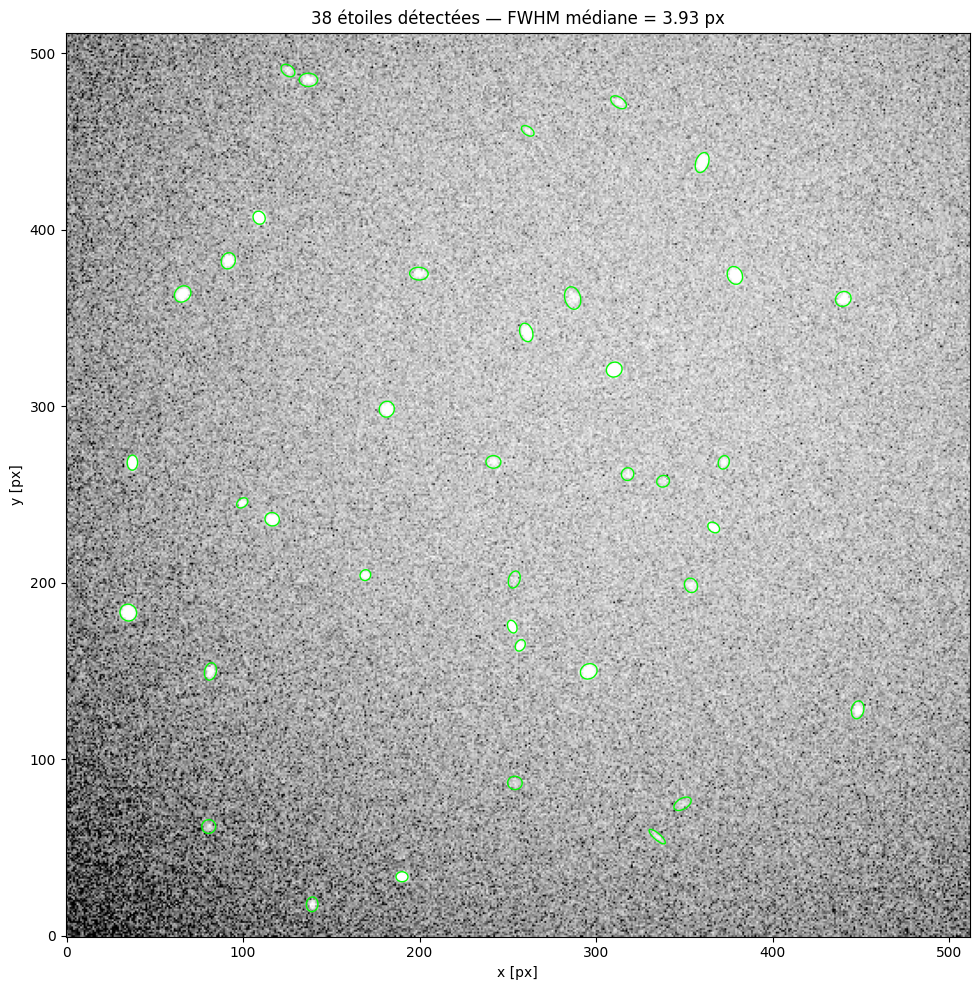

In [16]:
def show_detections(img, stars, scale=2.0, color="lime", figsize=(10, 10)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(stretch(img), cmap="gray", origin="lower")

    for s in stars:
        ell = Ellipse((s["x"], s["y"]),
                      width=scale * s["fwhm_a"], height=scale * s["fwhm_b"],
                      angle=s["theta"], fill=False, edgecolor=color, linewidth=1.0)
        ax.add_patch(ell)

    ax.set_title(f"{len(stars)} étoiles détectées — FWHM médiane = "
                 f"{np.median([s['fwhm'] for s in stars]):.2f} px")
    ax.set_xlabel("x [px]"); ax.set_ylabel("y [px]")
    plt.tight_layout()
    plt.show()


show_detections(image, stars)

## 7. Image t+1 : nouveau bruit, mêmes étoiles légèrement perturbées, décalage aléatoire

- **Nouveau bruit** : nouveau fond de ciel (nouveau tirage Poisson + lecture).
- **Décalage global** (pointage) : tiré une fois selon une gaussienne en x et en y.
- **Décalage individuel** : petit jitter gaussien propre à chaque étoile.
- **Étoiles similaires** : FWHM et flux perturbés de quelques % (variation de seeing et de transparence).

Décalage global injecté : dx = -0.84 px, dy = -1.25 px
60 étoiles restantes dans le champ sur 60


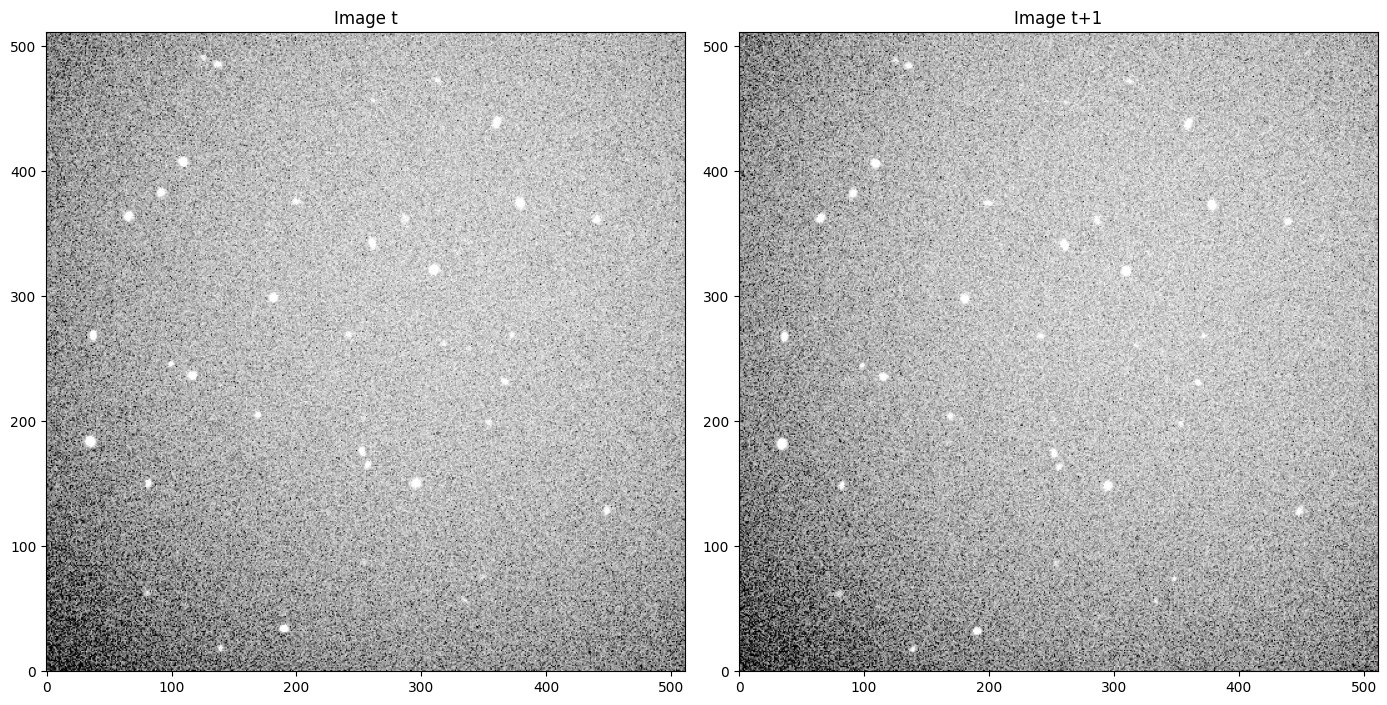

In [17]:
def make_next_frame(truth, shape=(512, 512), shift_sigma=4.0, jitter_sigma=0.4,
                    fwhm_scatter=0.05, flux_scatter=0.08, rng=rng):
    """Génère l'image t+1 à partir de la vérité terrain de l'image t.
    Retourne (image_t1, truth_t1 [x, y, flux, fwhm, e, theta, index_t], décalage global vrai)."""
    # Nouveau fond bruité (nouveau tirage de bruit)
    img = generate_noisy_background(shape=shape, rng=rng)

    # Décalage global gaussien en x et en y + variation globale du seeing
    global_shift = rng.normal(0, shift_sigma, size=2)
    seeing_factor = 1 + rng.normal(0, fwhm_scatter)

    truth_t1 = []
    ny, nx = shape
    for idx, (x, y, flux, fwhm, e, theta) in enumerate(truth):
        x_new = x + global_shift[0] + rng.normal(0, jitter_sigma)       # décalage moyen + particulier
        y_new = y + global_shift[1] + rng.normal(0, jitter_sigma)
        if not (0 <= x_new < nx and 0 <= y_new < ny):                    # étoile sortie du champ
            continue
        flux_new = flux * (1 + rng.normal(0, flux_scatter))
        fwhm_new = fwhm * seeing_factor * (1 + rng.normal(0, 0.02))
        e_new = np.clip(e + rng.normal(0, 0.03), 0, 0.4)
        theta_new = theta + rng.normal(0, 0.1)
        draw_star(img, x_new, y_new, flux_new, fwhm_new, e_new, theta_new, rng)
        truth_t1.append((x_new, y_new, flux_new, fwhm_new, e_new, theta_new, idx))

    return img, np.array(truth_t1), global_shift


image_t1, truth_t1, SHIFT_TRUE = make_next_frame(truth, shape=image.shape)
print(f"Décalage global injecté : dx = {SHIFT_TRUE[0]:+.2f} px, dy = {SHIFT_TRUE[1]:+.2f} px")
print(f"{len(truth_t1)} étoiles restantes dans le champ sur {len(truth)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, im, title in zip(axes, [image, image_t1], ["Image t", "Image t+1"]):
    ax.imshow(stretch(im), cmap="gray", origin="lower"); ax.set_title(title)
plt.tight_layout(); plt.show()

## 8. Détection des étoiles sur l'image t+1

Bruit estimé (t+1) : 15.42 ADU
36 étoiles détectées sur 60 injectées (t+1)


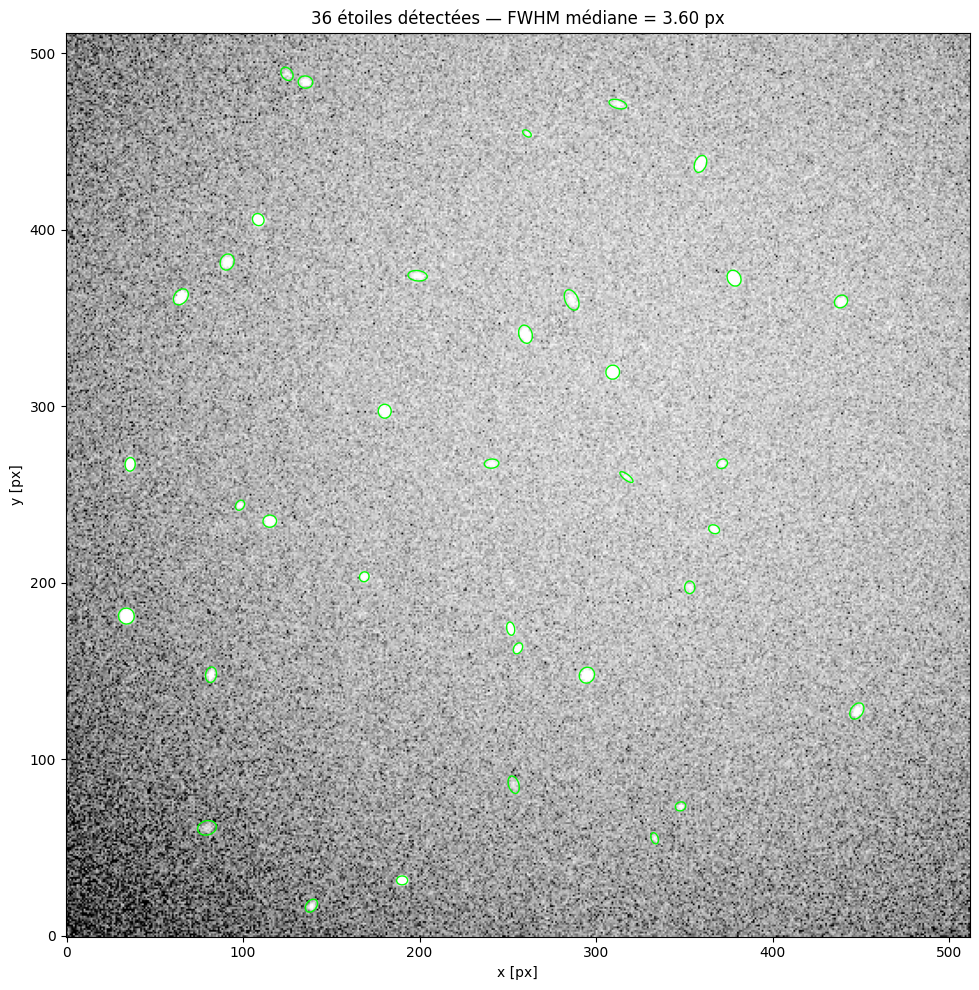

In [18]:
stars_t1, bg_t1, noise_t1 = detect_stars(image_t1)
print(f"Bruit estimé (t+1) : {noise_t1:.2f} ADU")
print(f"{len(stars_t1)} étoiles détectées sur {len(truth_t1)} injectées (t+1)")
show_detections(image_t1, stars_t1)

## 9. Étoile de référence\n\nL'étoile de référence est choisie à partir d'une **image** (détection avec `detect_stars`) : parmi les étoiles situées dans la zone centrale couvrant 50 % de la surface de l'image, on garde celle qui a la **meilleure FWHM** (la plus petite, donc la plus nette).

Étoile de référence (indice 17) : x_ref = 99.54, y_ref = 245.25, FWHM = 2.95 px


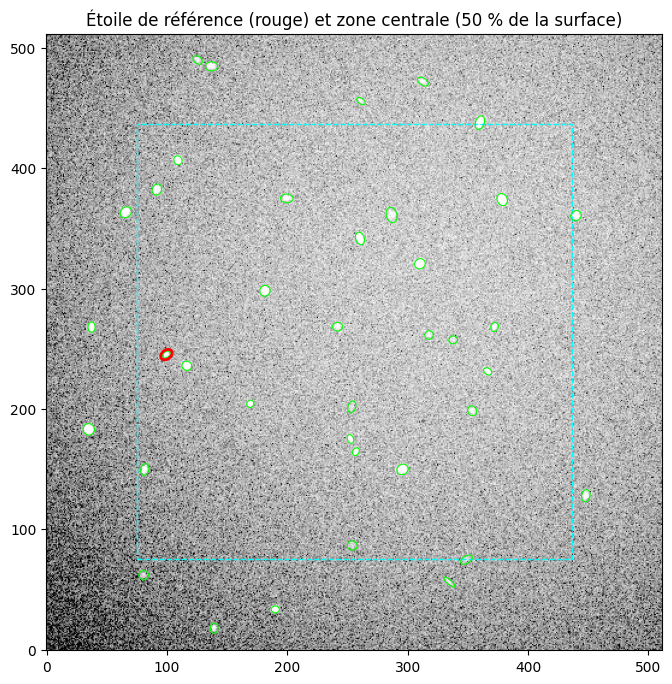

In [19]:
def find_reference_star(img, central_fraction=0.5, **detect_kwargs):
    """Détecte les étoiles de img et retourne (indice, étoile de référence, liste des étoiles).
    Zone centrale = rectangle centré, de même rapport d'aspect que l'image, couvrant
    `central_fraction` de la surface (côtés réduits d'un facteur sqrt(fraction))."""
    all_stars, _, _ = detect_stars(img, **detect_kwargs)
    ny, nx = img.shape
    f = np.sqrt(central_fraction)
    half_w, half_h = f * nx / 2, f * ny / 2
    cx, cy = nx / 2, ny / 2

    candidates = [i for i, s in enumerate(all_stars)
                  if abs(s["x"] - cx) <= half_w and abs(s["y"] - cy) <= half_h]
    if not candidates:
        raise ValueError("Aucune étoile dans la zone centrale")

    ref_idx = min(candidates, key=lambda i: all_stars[i]["fwhm"])    # meilleure FWHM = la plus petite
    return ref_idx, all_stars[ref_idx], all_stars


ref_idx, ref_star, _ = find_reference_star(image)
assert np.isclose(ref_star["x"], stars[ref_idx]["x"])               # même détection que la cellule 5
x_ref, y_ref = ref_star["x"], ref_star["y"]
print(f"Étoile de référence (indice {ref_idx}) : x_ref = {x_ref:.2f}, y_ref = {y_ref:.2f}, "
      f"FWHM = {ref_star['fwhm']:.2f} px")

# Visualisation : zone centrale (50 % de la surface) et étoile de référence en rouge
ny, nx = image.shape
f = np.sqrt(0.5)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(stretch(image), cmap="gray", origin="lower")
ax.add_patch(plt.Rectangle((nx / 2 * (1 - f), ny / 2 * (1 - f)), f * nx, f * ny,
                           fill=False, edgecolor="cyan", linestyle="--", linewidth=1))
for s in stars:
    ax.add_patch(Ellipse((s["x"], s["y"]), 2 * s["fwhm_a"], 2 * s["fwhm_b"], angle=s["theta"],
                         fill=False, edgecolor="lime", linewidth=0.8))
ax.add_patch(Ellipse((x_ref, y_ref), 3 * ref_star["fwhm_a"], 3 * ref_star["fwhm_b"],
                     angle=ref_star["theta"], fill=False, edgecolor="red", linewidth=2))
ax.set_title("Étoile de référence (rouge) et zone centrale (50 % de la surface)")
plt.show()

## 10. Appariement des étoiles t ↔ t+1\n\n1. **Décalage global** : vote sur l'histogramme 2D de toutes les différences de positions (robuste aux étoiles manquées/parasites), puis raffinement par médiane.\n2. **Appariement 1-à-1** optimal (algorithme hongrois) sur le coût = résidu de position après correction du décalage + écart de flux, avec une porte de rejet.\n3. **Ordre de la liste** : le premier tuple est la paire de l'étoile de référence ; le reste n'est pas trié.

In [20]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist


def estimate_global_shift(pos1, pos2, max_shift=25.0, bin_size=1.0, refine_radius=2.0):
    """Estime le décalage (dx, dy) pos1 -> pos2 par vote dans l'histogramme des différences."""
    diffs = (pos2[None, :, :] - pos1[:, None, :]).reshape(-1, 2)
    diffs = diffs[np.all(np.abs(diffs) < max_shift, axis=1)]
    edges = np.arange(-max_shift, max_shift + bin_size, bin_size)
    hist, xe, ye = np.histogram2d(diffs[:, 0], diffs[:, 1], bins=[edges, edges])
    hist = ndi.gaussian_filter(hist, 1.0)                      # tolère le jitter individuel
    ix, iy = np.unravel_index(np.argmax(hist), hist.shape)
    peak = np.array([(xe[ix] + xe[ix + 1]) / 2, (ye[iy] + ye[iy + 1]) / 2])
    close = np.linalg.norm(diffs - peak, axis=1) < refine_radius
    return np.median(diffs[close], axis=0)


def match_stars(stars_a, stars_b, ref_idx, sigma_pos=1.0, sigma_flux=0.25, gate=3.0):
    """Apparie les étoiles de deux listes de détections.
    Retourne (liste de tuples (i, j, score), décalage global estimé).
    Le premier tuple est la paire de l'étoile de référence (indice ref_idx dans stars_a) ;
    les autres tuples ne sont pas triés."""
    pos_a = np.array([[s["x"], s["y"]] for s in stars_a])
    pos_b = np.array([[s["x"], s["y"]] for s in stars_b])
    flux_a = np.array([s["flux"] for s in stars_a])
    flux_b = np.array([s["flux"] for s in stars_b])

    shift = estimate_global_shift(pos_a, pos_b)

    # Coût = distance résiduelle (après décalage) et différence de log-flux, en "sigmas"
    d_pos = cdist(pos_a + shift, pos_b)
    d_flux = np.abs(np.log(flux_a[:, None] / flux_b[None, :]))
    cost = np.sqrt((d_pos / sigma_pos) ** 2 + (d_flux / sigma_flux) ** 2)

    # Porte : on interdit les paires trop éloignées après correction
    cost_gated = np.where(d_pos > gate * sigma_pos, 1e6, cost)
    rows, cols = linear_sum_assignment(cost_gated)

    matches = [(int(i), int(j), float(cost[i, j])) for i, j in zip(rows, cols)
               if cost_gated[i, j] < 1e6]

    # L'étoile de référence passe en tête de liste, le reste garde son ordre
    k = next((n for n, m in enumerate(matches) if m[0] == ref_idx), None)
    if k is None:
        raise ValueError("L'étoile de référence n'a pas de correspondance dans l'image t+1")
    matches.insert(0, matches.pop(k))
    return matches, shift


matches, shift_est = match_stars(stars, stars_t1, ref_idx)
i_ref, j_ref, _ = matches[0]
print(f"Décalage estimé : dx = {shift_est[0]:+.2f}, dy = {shift_est[1]:+.2f} px "
      f"(injecté : {SHIFT_TRUE[0]:+.2f}, {SHIFT_TRUE[1]:+.2f})")
print(f"Référence : ({stars[i_ref]['x']:.2f}, {stars[i_ref]['y']:.2f}) à t -> "
      f"({stars_t1[j_ref]['x']:.2f}, {stars_t1[j_ref]['y']:.2f}) à t+1")
print(f"{len(matches)} paires appariées\n")

print(" pos | idx t | idx t+1 | score |  (x, y) t        ->  (x, y) t+1")
for n, (i, j, score) in enumerate(matches[:10]):
    a, b = stars[i], stars_t1[j]
    tag = "  <- référence" if n == 0 else ""
    print(f"{n:4d} | {i:5d} | {j:7d} | {score:5.2f} | ({a['x']:6.1f}, {a['y']:6.1f}) -> ({b['x']:6.1f}, {b['y']:6.1f}){tag}")
print("...")

# Vérification contre la vérité terrain
def nearest_truth(star, tr):
    return int(np.argmin(np.hypot(tr[:, 0] - star["x"], tr[:, 1] - star["y"])))

correct = 0
for i, j, _ in matches:
    ti = nearest_truth(stars[i], truth)                       # étoile vraie à t
    tj = nearest_truth(stars_t1[j], truth_t1)                 # étoile vraie à t+1
    correct += int(truth_t1[tj, 6] == ti)
print(f"\nPaires correctes (vs vérité terrain) : {correct}/{len(matches)}")

Décalage estimé : dx = -0.79, dy = -1.12 px (injecté : -0.84, -1.25)
Référence : (99.54, 245.25) à t -> (98.29, 243.92) à t+1
36 paires appariées

 pos | idx t | idx t+1 | score |  (x, y) t        ->  (x, y) t+1
   0 |    17 |      16 |  0.60 | (  99.5,  245.3) -> (  98.3,  243.9)  <- référence
   1 |     0 |       0 |  0.56 | ( 139.1,   17.8) -> ( 138.7,   17.1)
   2 |     1 |       1 |  1.34 | ( 190.0,   33.5) -> ( 190.1,   31.4)
   3 |     2 |       2 |  1.09 | ( 334.6,   56.2) -> ( 333.1,   55.3)
   4 |     3 |       3 |  1.18 | (  80.5,   61.9) -> (  79.6,   61.2)
   5 |     4 |       4 |  0.50 | ( 348.9,   74.8) -> ( 347.8,   73.3)
   6 |     5 |       5 |  0.73 | ( 254.0,   86.6) -> ( 253.3,   85.6)
   7 |     6 |       6 |  0.58 | ( 448.1,  128.0) -> ( 447.7,  127.3)
   8 |     7 |       7 |  1.37 | (  81.5,  149.8) -> (  81.8,  147.9)
   9 |     8 |       8 |  1.31 | ( 295.8,  149.8) -> ( 294.8,  147.7)
...

Paires correctes (vs vérité terrain) : 36/36
